/var/folders/hq/5zr3b9p93_z1mjg_66l_kvlc0000gn/T/ipykernel_15880/3484317082.py:87: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


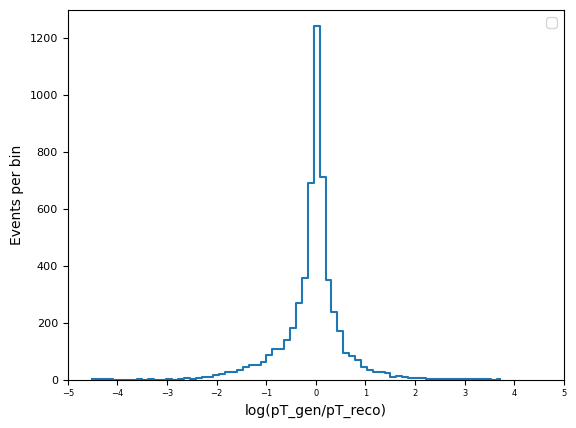

In [ ]:
import pythia8
import fastjet
import numpy as np
import matplotlib.pyplot as plt


file = pythia8.Pythia()
file.readString("Beams:frameType = 4") # Option 4 = Read LHE file
file.readString("Beams:LHEF = unweighted_events.lhe")
file.init()
B_Meson=[511, 521, 10511, 10521, 513, 523, 10513, 10523, 
    20513, 20523, 515, 525, 531, 10531, 533, 10533, 
    20533, 535, 541, 10541, 543, 10543, 20543, 545]     #pdg id's of all b mesons

def comes_from_b_meson(event, start_index):     #to check if the final state particle decayed from a b meson
        curr_index=start_index
        while curr_index>0:     #the loop breaks when we reach the particle which started the process (Z-boson in this case)
            prt=event[curr_index]       #here prt is a local variable
            if prt.idAbs() in B_Meson:
                return True
            curr_index=prt.mother1()    #if not true, the loop contunies to track the mothers of subsequent particles
        return False


pT_gen=[]       #pT from true event information: pTgen
pT_reco=[]      #pT from reconstructed jets: pTreco
px_tot=[]       #for storing x and y momentum of b and b bar quarks from which we will calculate pTreco
py_tot=[]


while file.next():      #produces showers of particles 
    """First step: jet reconstruction and jet tagging"""
    final_event_prt=[]  #for storing 4-momentum of all final state particles
    i=0             #for providing index to each final state particle
    for prt in file.event:
        if prt.status()>0:
            four_p=fastjet.PseudoJet(prt.px(), prt.py(), prt.pz(), prt.e()) #storing 4-momentum
            four_p.set_user_index(i)    #provided index with PseudoJet object
            final_event_prt.append(four_p)      #list of 4-momenta of final particles
        i+=1

    jetdef = fastjet.JetDefinition(fastjet.antikt_algorithm, 0.4)   #defines jet recontruction algorithm with R=0.4
    cluster = fastjet.ClusterSequence(final_event_prt, jetdef)      #produces clusters of jets acc in the form of a tuple
    jets = list(cluster.inclusive_jets(ptmin=20.0))   #converts tuple to list of reconstructed jets with pT>20 GeV

    

    b_jets=[]   #list of jets which have b mesons
    for jet in jets:        #jets only contain final state particles
        prt_list=jet.constituents()     #list of partcles in this jet
        for prt in prt_list:        #this prt is different from the one defined earlier (prt in jet)
            prt_index=prt.user_index() #index of that particle which was assigned earlier
            if comes_from_b_meson(file.event, prt_index):    #checking if it originated from B meson
                b_jets.append(jet)
                break   #shortens runtime

    """second step: finding pT_reco from jets and storing 
    pT_gen only for those events which have >=2 b-tagged jets
    """
    if len(b_jets)>=2:      #incase we get more than two jets tagged as b jets
        b_jets.sort(key=lambda j: j.pt(), reverse=True)
        final_four_p=b_jets[0]+b_jets[1]
        pT_reco.append(final_four_p.pt())

        all_bquarks=[prt for prt in file.event if prt.idAbs() == 5 and 21 <= abs(prt.status()) <= 29]   #this list is created from the history of the final particle (b quarks decay further into mesons, muons)
        if len(all_bquarks)>=2:     #must have at least two bottom quarks in the event
            all_bquarks.sort(key=lambda particle: particle.pT(), reverse=True)
            px_tot.append(all_bquarks[0].px()+all_bquarks[1].px())
            py_tot.append(all_bquarks[0].py()+all_bquarks[1].py())
    
px_tot=np.array(px_tot)
py_tot=np.array(py_tot)
pT_gen= np.sqrt(px_tot**2+py_tot**2)      
            
                     
pT_reco=np.array(pT_reco)
pT_gen=np.array(pT_gen)


"""third step: dividing the two and taking log
to obtain the correction factor"""

y=np.log(pT_gen/pT_reco)
histy, bin_edges = np.histogram(y, bins=70)
bin_centers = 0.5*(bin_edges[1:] + bin_edges[:-1])


"""Fourth step: plotting to see the results"""

plt.plot(bin_centers,histy,drawstyle = 'steps-mid')
plt.xlabel('log(pT_gen/pT_reco)', fontsize=10)
plt.ylabel('Events per bin', fontsize=10)
plt.ylim(0,1300) #Label y
plt.xlim(-5,5)
plt.xticks(np.arange(-5,6,1),fontsize=6)
plt.yticks(fontsize=8)
plt.legend()
plt.show()



